<a href="https://colab.research.google.com/github/GauravGhatte/DMDW/blob/main/DMDW_Diabetes_Risk_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client\.session"
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [16]:
%pip -q install mlxtend

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, silhouette_score
)
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")

Libraries imported successfully.


In [17]:
columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

try:
    df = pd.read_csv(url, header=None, names=columns)
except Exception as e:
    print("Automatic download failed. Upload the CSV file in Colab and load it manually.")
    raise e

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe().round(2))

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


In [18]:
print("Data types:")
display(df.dtypes.to_frame("Data type"))
print("Missing values before cleaning:")
display(df.isna().sum().to_frame("Missing values"))

df = df.drop_duplicates().copy()

zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)

print("Missing values after treating invalid zeros as missing:")
display(df.isna().sum().to_frame("Missing values"))
print("Shape after removing duplicates:", df.shape)

Data types:


,Data type
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


Missing values before cleaning:


,Missing values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Missing values after treating invalid zeros as missing:


,Missing values
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Shape after removing duplicates: (768, 9)


In [19]:
feature_cols = [c for c in df.columns if c != "Outcome"]
X_raw = df[feature_cols].copy()
y = df["Outcome"].astype(int).copy()

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X_raw), columns=feature_cols, index=df.index)

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_imputed), columns=feature_cols, index=df.index)

print("Missing values after imputation:", int(X_imputed.isna().sum().sum()))
display(X_imputed.head())
display(X_scaled.head())

Missing values after imputation: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.0,125.0,33.6,0.627,50.0
1,1.0,85.0,66.0,29.0,125.0,26.6,0.351,31.0
2,8.0,183.0,64.0,29.0,125.0,23.3,0.672,32.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.639947,0.866045,-0.031990,0.670643,-0.181541,0.166619,0.468492,1.425995
1,-0.844885,-1.205066,-0.528319,-0.012301,-0.181541,-0.852200,-0.365061,-0.190672
2,1.233880,2.016662,-0.693761,-0.012301,-0.181541,-1.332500,0.604397,-0.105584
3,-0.844885,-1.073567,-0.528319,-0.695245,-0.540642,-0.633881,-0.920763,-1.041549
4,-1.141852,0.504422,-2.679076,0.670643,0.316566,1.549303,5.484909,-0.020496


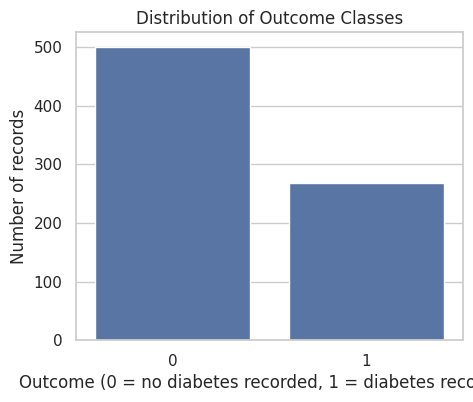

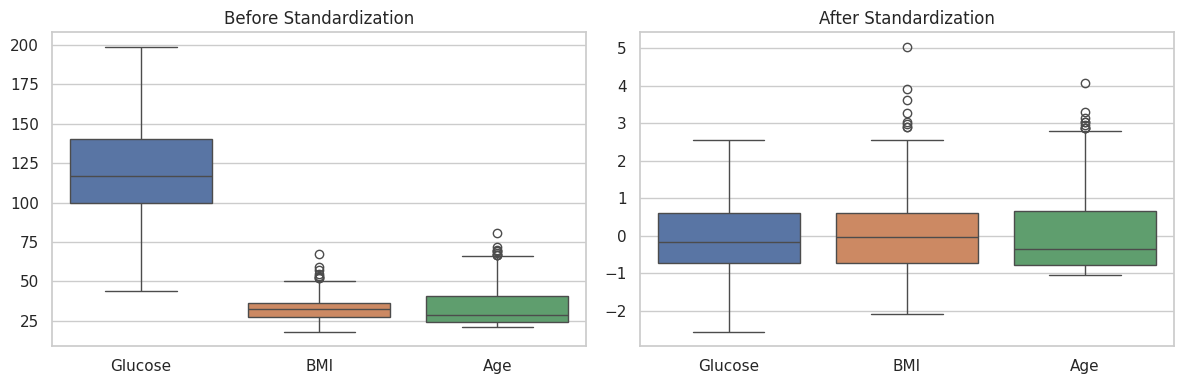

In [20]:
plt.figure(figsize=(5, 4))
sns.countplot(x=y)
plt.title("Distribution of Outcome Classes")
plt.xlabel("Outcome (0 = no diabetes recorded, 1 = diabetes recorded)")
plt.ylabel("Number of records")
plt.show()

compare_cols = ["Glucose", "BMI", "Age"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=X_imputed[compare_cols], ax=axes[0])
axes[0].set_title("Before Standardization")
sns.boxplot(data=X_scaled[compare_cols], ax=axes[1])
axes[1].set_title("After Standardization")
plt.tight_layout()
plt.show()

In [21]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
clustered_df = X_imputed.copy()
clustered_df["Cluster"] = clusters
clustered_df["Outcome"] = y.values

sil_score = silhouette_score(X_scaled, clusters)
print(f"Silhouette score for K-Means: {sil_score:.3f}")
print("Records per cluster:")
display(clustered_df["Cluster"].value_counts().sort_index().to_frame("Records"))
print("Outcome distribution within each cluster (descriptive only):")
display(pd.crosstab(clustered_df["Cluster"], clustered_df["Outcome"], normalize="index").round(3))

Silhouette score for K-Means: 0.196
Records per cluster:


,Records
Cluster,
0,351
1,417


Outcome distribution within each cluster (descriptive only):


Outcome,0,1
Cluster,,
0,0.444,0.556
1,0.825,0.175


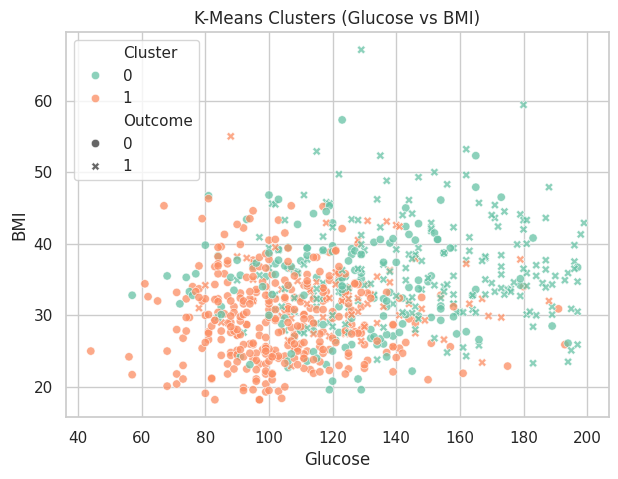

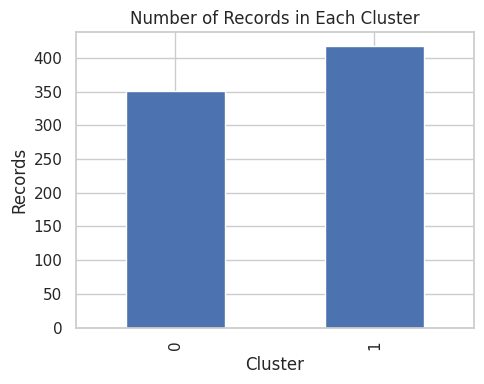

In [22]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=clustered_df, x="Glucose", y="BMI",
    hue="Cluster", style="Outcome", palette="Set2", alpha=0.75
)
plt.title("K-Means Clusters (Glucose vs BMI)")
plt.show()

cluster_counts = clustered_df["Cluster"].value_counts().sort_index()
cluster_counts.plot(kind="bar", figsize=(5, 4), title="Number of Records in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.20, random_state=42, stratify=y
)

# A Decision Tree is interpretable and suitable for a mini-project demonstration.
classifier = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight="balanced")
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1]
})
display(metrics.round(3))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Outcome 0", "Outcome 1"], zero_division=0))

,Metric,Score
0,Accuracy,0.708
1,Precision,0.556
2,Recall,0.833
3,F1-score,0.667



Classification report:
              precision    recall  f1-score   support

   Outcome 0       0.88      0.64      0.74       100
   Outcome 1       0.56      0.83      0.67        54

    accuracy                           0.71       154
   macro avg       0.72      0.74      0.70       154
weighted avg       0.76      0.71      0.71       154



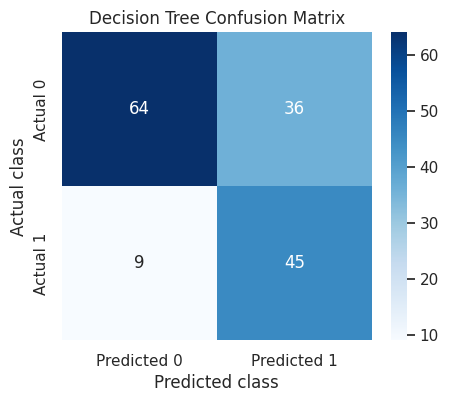

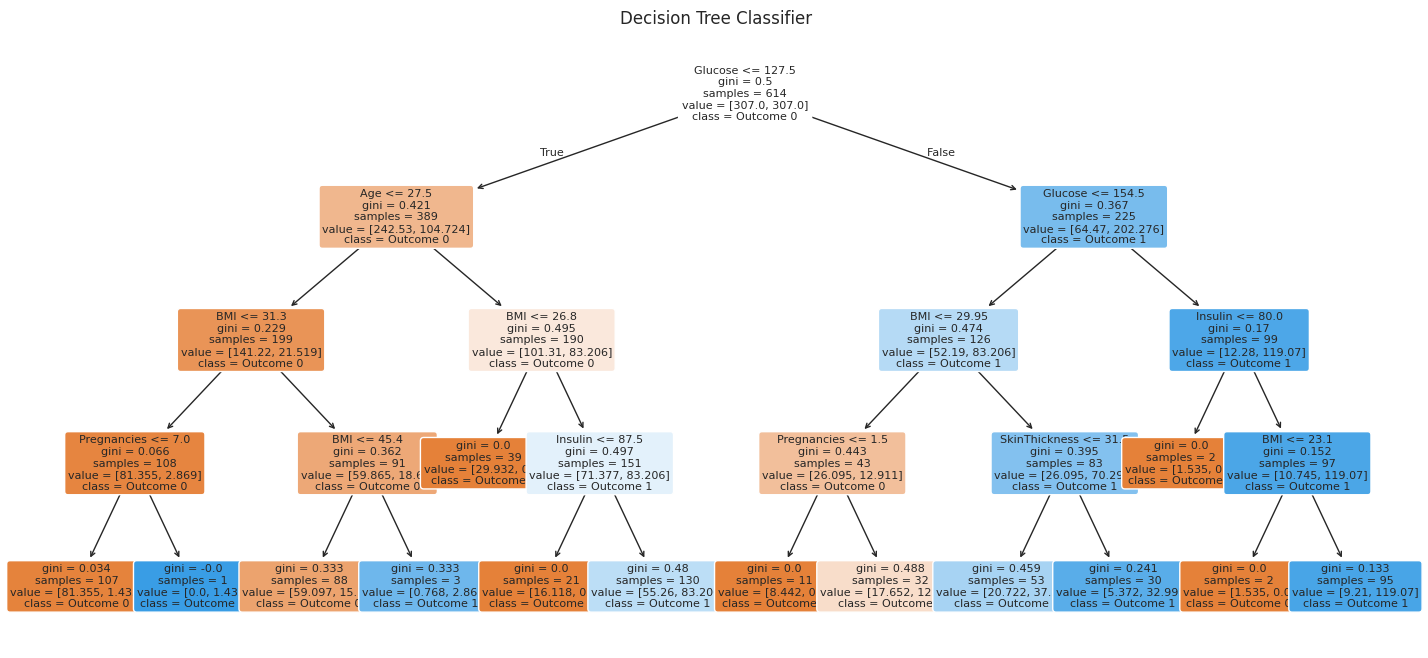

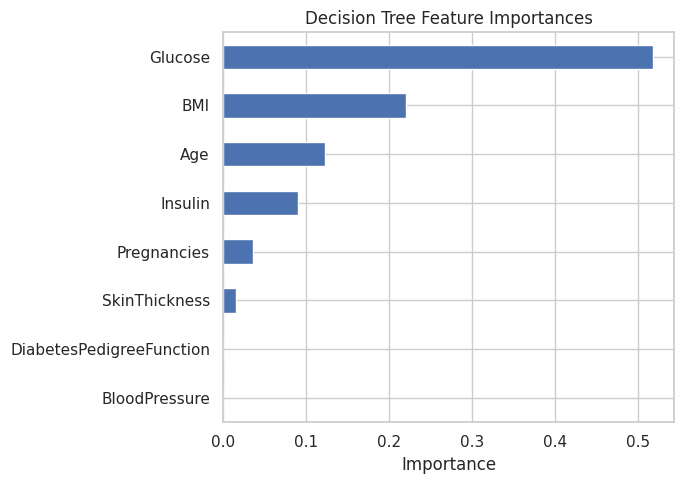

In [24]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"])
plt.title("Decision Tree Confusion Matrix")
plt.ylabel("Actual class")
plt.xlabel("Predicted class")
plt.show()

plt.figure(figsize=(18, 8))
plot_tree(classifier, feature_names=feature_cols,
          class_names=["Outcome 0", "Outcome 1"],
          filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree Classifier")
plt.show()

pd.Series(classifier.feature_importances_, index=feature_cols).sort_values().plot(
    kind="barh", figsize=(7, 5), title="Decision Tree Feature Importances"
)
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [25]:
# Create readable categories from the imputed measurements.
# Use qcut with integer labels first, so tied quantile boundaries do not cause an error.
rule_data = pd.DataFrame(index=X_imputed.index)

for col in ["Glucose", "BMI", "Age", "BloodPressure"]:
    bin_ids = pd.qcut(X_imputed[col], q=3, labels=False, duplicates="drop")
    n_bins = int(pd.Series(bin_ids).nunique())
    category_names = {0: "Low", 1: "Medium", 2: "High"}
    rule_data[col + "_level"] = pd.Series(bin_ids, index=X_imputed.index).map(category_names).astype(str)

rule_data["Outcome"] = y.map({0: "No_diabetes_recorded", 1: "Diabetes_recorded"}).values

# One-hot encode categorical items for Apriori.
transactions = pd.get_dummies(rule_data.astype(str), prefix_sep="=").astype(bool)

frequent_itemsets = apriori(transactions, min_support=0.08, use_colnames=True)
print("Frequent itemsets found:", len(frequent_itemsets))
display(frequent_itemsets.sort_values("support", ascending=False).head(10))

Frequent itemsets found: 106


,support,itemsets
13,0.651042,(Outcome=No_diabetes_recorded)
10,0.368490,(BloodPressure_level=Low)
12,0.348958,(Outcome=Diabetes_recorded)
7,0.347656,(Age_level=Low)
4,0.338542,(BMI_level=Low)
1,0.337240,(Glucose_level=Low)
2,0.335938,(Glucose_level=Medium)
3,0.333333,(BMI_level=High)
6,0.330729,(Age_level=High)
5,0.328125,(BMI_level=Medium)


In [26]:
if len(frequent_itemsets) >= 2:
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.55)
    if not rules.empty:
        rules["antecedents"] = rules["antecedents"].apply(lambda x: ", ".join(sorted(list(x))))
        rules["consequents"] = rules["consequents"].apply(lambda x: ", ".join(sorted(list(x))))
        rules = rules.sort_values(["lift", "confidence"], ascending=False)
        display(rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(15).round(3))
    else:
        print("No rules met the chosen confidence threshold. Try lowering min_threshold to 0.4.")
else:
    print("No frequent itemsets found at this support threshold. Try lowering min_support to 0.05.")

,antecedents,consequents,support,confidence,lift
64,"Age_level=Low, BMI_level=Low","BloodPressure_level=Low, Outcome=No_diabetes_r...",0.100,0.670,2.414
58,"Age_level=Low, Glucose_level=Low","BloodPressure_level=Low, Outcome=No_diabetes_r...",0.099,0.623,2.246
52,"BMI_level=Low, Glucose_level=Low","BloodPressure_level=Low, Outcome=No_diabetes_r...",0.089,0.618,2.229
12,"BMI_level=High, Glucose_level=High",Outcome=Diabetes_recorded,0.103,0.752,2.156
57,"BloodPressure_level=Low, Glucose_level=Low","Age_level=Low, Outcome=No_diabetes_recorded",0.099,0.608,2.103
63,"BMI_level=Low, BloodPressure_level=Low","Age_level=Low, Outcome=No_diabetes_recorded",0.100,0.602,2.081
13,"BMI_level=High, Outcome=Diabetes_recorded",Glucose_level=High,0.103,0.648,1.981
20,"BloodPressure_level=High, Outcome=Diabetes_rec...",Glucose_level=High,0.090,0.645,1.973
47,"BMI_level=Low, Glucose_level=Low","Age_level=Low, Outcome=No_diabetes_recorded",0.081,0.564,1.950
15,"BloodPressure_level=High, Glucose_level=High",Age_level=High,0.091,0.631,1.907


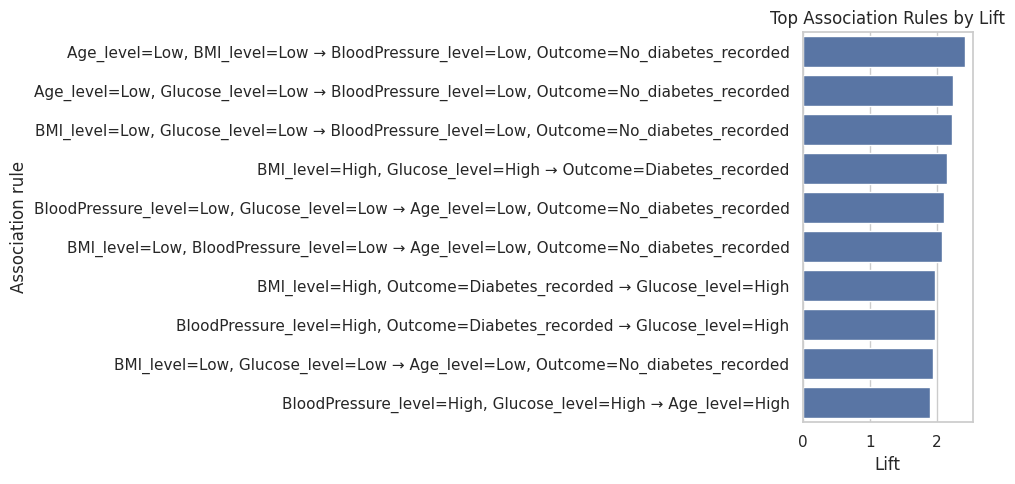

In [27]:
# Visualize the strongest rules, if any were found.
try:
    plot_rules = rules.head(10).copy()
    if not plot_rules.empty:
        plot_rules["Rule"] = plot_rules["antecedents"] + " → " + plot_rules["consequents"]
        plt.figure(figsize=(10, 5))
        sns.barplot(data=plot_rules, x="lift", y="Rule")
        plt.title("Top Association Rules by Lift")
        plt.xlabel("Lift")
        plt.ylabel("Association rule")
        plt.tight_layout()
        plt.show()
    else:
        print("No association rules to plot.")
except NameError:
    print("No association rules to plot.")

In [28]:
summary = pd.DataFrame({
    "Technique": ["K-Means Clustering", "Decision Tree Classification", "Apriori Association Rules"],
    "Evaluation / output": [
        f"Silhouette score = {sil_score:.3f}",
        f"Accuracy = {accuracy:.3f}, Precision = {precision:.3f}, Recall = {recall:.3f}, F1 = {f1:.3f}",
        f"Frequent itemsets = {len(frequent_itemsets)}, rules = {len(rules) if 'rules' in globals() else 0}"
    ]
})
display(summary)

,Technique,Evaluation / output
0,K-Means Clustering,Silhouette score = 0.196
1,Decision Tree Classification,"Accuracy = 0.708, Precision = 0.556, Recall = ..."
2,Apriori Association Rules,"Frequent itemsets = 106, rules = 65"
